## My first Python notebook

This notebook records the prompts, code, checks, and interpretations from Week 4.

In [ ]:
print("A changed message!")

A changed message!


In [ ]:
number_of_books = 500

In [ ]:
print(number_of_books)

500


Prompt used:
"I am a digital humanities student with no previous Python experience working in Google Colab. Write one self-contained Python code cell using pandas to inspect a CSV named "book-sample.csv".\
\
Each row represents one recorded edition in a teaching sample. The columns are: edition_id, short_title, author, printer, place, year, language, format, country, year_numeric, decade.\
\
Here is a short excerpt from the beginning of the file:\


| **edition_id** | **short_title**                                                                                                                                | **author**            | **printer**        | **place**  | **year** | **language** | **format** | **country**         | **year_numeric** | **decade** |
| -------------- | ---------------------------------------------------------------------------------------------------------------------------------------------- | --------------------- | ------------------ | ---------- | -------- | ------------ | ---------- | ------------------- | ---------------- | ---------- |
| 627908         | Das Newe   Testament                                                                                                                           |                       | Kunigunde   Hergot | Nürnberg   | 1535     | German       | 8o         | Holy Roman   Empire | 1535             | 1530s      |
| 698366         | Trewung vom liebebande oder hertztrewen. Item:   hochzeitpredigt von den ursachen warumb einer gerne Freyen solle                              | Streuber, Peter       | Zacharias Bärwald  | Leipzig    | 1590     | German       | 8o         | Holy Roman Empire   | 1590             | 1590s      |
| 691468         | Romischer   Keyserlicher Majestat ordnung und Reformation gueter pollicei im heyligen   Roemischen Reich anno M.D.XXX. zä Augspurg uffgericht. |                       | Johann Schöffer    | Mainz      | 1530     | German       | 2o         | Holy Roman   Empire | 1530             | 1530s      |
| 708446         | Zwo predigten vom gantzen Christlichen wesen und leben                                                                                         | Spangenberg, Cyriacus | Samuel Emmel       | Strasbourg | 1564     | German       | 8o         | Holy Roman Empire   | 1564             | 1560s      |

\
\
The code must:\
1\. load the CSV without changing it;\
2\. print the number of rows and columns;\
3\. display the first five rows;\
4\. print every column name and data type;\
5\. print the number and percentage of missing values in every column;\
6\. calculate minimum, median, mean, and maximum of year_numeric;\
7\. count records by decade, country, language, and format, including missing categories;\
8\. check whether edition_id is unique;\
9\. use clear labels so a beginner can interpret each output.\
\
Do not drop, fill, or overwrite any values. After the code, explain it in plain language and identify what these statistics cannot establish historically."

In [2]:

# ============================================================
# EXPLORATORY DATA ANALYSIS: HISTORICAL BOOK EDITIONS
# File: book-sample.csv
# ============================================================

import pandas as pd
from IPython.display import display

# STEP 1: Load the CSV file
# Upload book-sample.csv to Google Colab when prompted.
from google.colab import files
uploaded = files.upload()

# Read the file into a pandas DataFrame.
# This does not change the original CSV file.
df = pd.read_csv("book-sample.csv")

# STEP 2: Count rows and columns
print("\n=== 1. DATASET SIZE ===")
print(f"Number of rows (recorded editions): {df.shape[0]}")
print(f"Number of columns (variables): {df.shape[1]}")

# STEP 3: Display the first five rows
print("\n=== 2. FIRST FIVE RECORDS ===")
display(df.head(5))

# STEP 4: Show column names and data types
print("\n=== 3. COLUMN NAMES AND DATA TYPES ===")
for column in df.columns:
    print(f"{column}: {df[column].dtype}")

# STEP 5: Count and calculate percentages of missing values
print("\n=== 4. MISSING VALUES BY COLUMN ===")
missing = pd.DataFrame({
    "Missing values (count)": df.isna().sum(),
    "Missing values (%)": (df.isna().mean() * 100).round(2)
})
display(missing)

# STEP 6: Calculate summary statistics for year_numeric
print("\n=== 5. PUBLICATION YEAR STATISTICS ===")

# Convert to numeric for calculation only.
# Invalid or non-numeric entries are treated as missing
# in this temporary calculation, not changed in the dataset.
years = pd.to_numeric(df["year_numeric"], errors="coerce")

print(f"Minimum publication year: {years.min()}")
print(f"Median publication year: {years.median()}")
print(f"Mean publication year: {years.mean():.2f}")
print(f"Maximum publication year: {years.max()}")

# STEP 7: Count records by historical categories
print("\n=== 6. FREQUENCY COUNTS BY CATEGORY ===")

for column in ["decade", "country", "language", "format"]:
    print(f"\n--- Number of records by {column} ---")

    # dropna=False includes missing categories in the counts.
    counts = df[column].value_counts(dropna=False)

    display(counts.rename("Number of records").to_frame())

# STEP 8: Check whether edition_id is unique
print("\n=== 7. EDITION ID UNIQUENESS CHECK ===")

unique_ids = df["edition_id"].is_unique
duplicate_count = df["edition_id"].duplicated(keep=False).sum()

print(f"Is every edition_id unique? {unique_ids}")
print(f"Number of rows with a repeated edition_id: {duplicate_count}")

if unique_ids:
    print("Result: Every row has a distinct edition_id.")
else:
    print("Result: Some edition_id values occur more than once.")
    print("These records may require further investigation.")

print("\n=== ANALYSIS COMPLETE ===")
print("The original CSV file and DataFrame values were not modified.")


Saving book-sample.csv to book-sample (1).csv

=== 1. DATASET SIZE ===
Number of rows (recorded editions): 500
Number of columns (variables): 11

=== 2. FIRST FIVE RECORDS ===


,edition_id,short_title,author,printer,place,year,language,format,country,year_numeric,decade
0,627908,Das Newe Testament,NaN,Kunigunde Hergot,Nürnberg,1535,German,8o,Holy Roman Empire,1535,1530s
1,698366,Trewung vom liebebande oder hertztrewen. Item:...,"Streuber, Peter",Zacharias Bärwald,Leipzig,1590,German,8o,Holy Roman Empire,1590,1590s
2,691468,Romischer Keyserlicher Majestat ordnung und Re...,NaN,Johann Schöffer,Mainz,1530,German,2o,Holy Roman Empire,1530,1530s
3,708446,Zwo predigten vom gantzen Christlichen wesen u...,"Spangenberg, Cyriacus",Samuel Emmel,Strasbourg,1564,German,8o,Holy Roman Empire,1564,1560s
4,640867,"Corpus juris civilis, institutiones dn. Joachi...",NaN,Nikolaus II Episcopius,Basel,1555,Latin,2o,Swiss Confederation,1555,1550s



=== 3. COLUMN NAMES AND DATA TYPES ===
edition_id: int64
short_title: object
author: object
printer: object
place: object
year: object
language: object
format: object
country: object
year_numeric: int64
decade: object

=== 4. MISSING VALUES BY COLUMN ===


,Missing values (count),Missing values (%)
edition_id,0,0.0
short_title,0,0.0
author,100,20.0
printer,0,0.0
place,0,0.0
year,0,0.0
language,14,2.8
format,19,3.8
country,0,0.0
year_numeric,0,0.0



=== 5. PUBLICATION YEAR STATISTICS ===
Minimum publication year: 1501
Median publication year: 1554.0
Mean publication year: 1553.49
Maximum publication year: 1600

=== 6. FREQUENCY COUNTS BY CATEGORY ===

--- Number of records by decade ---


,Number of records
decade,
1550s,67
1520s,64
1560s,58
1570s,54
1580s,53
1540s,50
1530s,50
1590s,47
1510s,33


... (3 outputs left out)

,Number of records
language,
Latin,200
German,168
Greek,31
French,21
NaN,14
Hebrew,14
Italian,13
English,10
Dutch,10



--- Number of records by format ---


,Number of records
format,
8o,217
4o,180
2o,54
NaN,19
Broadsheet,11
16o,7
8o oblong,6
12o,4
4o oblong,2



=== 7. EDITION ID UNIQUENESS CHECK ===
Is every edition_id unique? True
Number of rows with a repeated edition_id: 0
Result: Every row has a distinct edition_id.

=== ANALYSIS COMPLETE ===
The original CSV file and DataFrame values were not modified.


Prompt used:
"I am a digital humanities student with no previous Python experience working in Google Colab. Write one self-contained Python code cell using pandas and Python's standard re module to transform "historic_photographs_sample_dataset.csv" for later use in RAWGraphs.

Each input row represents one photograph metadata record. The input has 100 rows and these columns:
record_id, title_raw, creator_raw, date_raw, place_raw, country_raw, subject_raw, object_type_raw, caption_language_raw, holding_institution_raw, rights_raw, box_folder_raw, filename_raw, notes_raw, creator_authority_uri, place_wikidata_qid, lcsh_subjects.

Requirements:
- Preserve all original columns and all 100 rows.
- Do not overwrite, fill, or delete raw values.
- Add year_start: the first four-digit year in date_raw, stored as a nullable integer.
- Add year_end: the second four-digit year when present; otherwise use year_start, stored as a nullable integer.
- Add date_certainty using this explicit precedence: "uncertain" if date_raw contains ?, otherwise "approximate" if it begins with c. after trimming and lowercasing, otherwise "supplied/inferred" if it begins with [, otherwise "range" if it contains two four-digit years, otherwise "exact" if it contains one four-digit year, otherwise "unparsed".
- Add place_trimmed by removing leading and trailing whitespace from place_raw. Do not translate or otherwise standardize place names.
- Print input and output row counts, the number of unique record_id values, missing counts for every newly created column, and a table containing date_raw plus the three derived date columns for at least ten representative rows.
- Assert that the output has 100 rows, that record_id remains unique, and that no original column has been removed.
- Save the record-level transformed table as "photographs_for_rawgraphs.csv" with UTF-8 encoding and without a pandas index.
- Create a second DataFrame that groups the transformed records by date_certainty and counts the number of records in each category. It must have exactly two columns named date_certainty and record_count, with one row per date_certainty category. Include every category, including "unparsed".
- Print this aggregated table and assert that record_count sums to 100.
- Save the aggregated table as "date_certainty_counts_for_rawgraphs.csv" with UTF-8 encoding and without a pandas index.
- Do not use Google Drive mounting or any library other than pandas and Python's standard library.

After the code, explain every transformation, explain how aggregation changes the unit of observation, and identify cases that the rules might handle incorrectly."

In [3]:

import pandas as pd
import re

# --------------------------------------------------
# 1. Read the original CSV file
# --------------------------------------------------

df = pd.read_csv(
    "historic_photographs_sample_dataset.csv",
    dtype="string",
    keep_default_na=False
)

# Remember the original columns and number of rows
original_columns = df.columns.tolist()
input_row_count = len(df)

# Make a copy so the original data stays unchanged
transformed = df.copy()


# --------------------------------------------------
# 2. Extract years from date_raw
# --------------------------------------------------

def extract_years(date_value):
    # Find all four-digit numbers in the date
    years = re.findall(r"(?<!\d)\d{4}(?!\d)", date_value)

    if len(years) == 0:
        return pd.NA, pd.NA

    year_start = int(years[0])

    if len(years) >= 2:
        year_end = int(years[1])
    else:
        year_end = year_start

    return year_start, year_end


# Apply the function to every date
year_pairs = transformed["date_raw"].apply(extract_years)

transformed["year_start"] = pd.array(
    [pair[0] for pair in year_pairs],
    dtype="Int64"
)

transformed["year_end"] = pd.array(
    [pair[1] for pair in year_pairs],
    dtype="Int64"
)


# --------------------------------------------------
# 3. Classify date certainty
# --------------------------------------------------

def classify_date(date_value):
    date = date_value.strip().lower()

    # The order of these conditions is important!

    if "?" in date:
        return "uncertain"

    elif date.startswith("c."):
        return "approximate"

    elif date.startswith("["):
        return "supplied/inferred"

    # Count four-digit years
    years = re.findall(r"(?<!\d)\d{4}(?!\d)", date)

    if len(years) >= 2:
        return "range"

    elif len(years) == 1:
        return "exact"

    else:
        return "unparsed"


transformed["date_certainty"] = (
    transformed["date_raw"].apply(classify_date)
)


# --------------------------------------------------
# 4. Trim whitespace from place_raw
# --------------------------------------------------

transformed["place_trimmed"] = (
    transformed["place_raw"].str.strip()
)

# Note: place_raw itself is not modified.


# --------------------------------------------------
# 5. Validate the transformed dataset
# --------------------------------------------------

output_row_count = len(transformed)

assert output_row_count == 100, "Expected exactly 100 rows."

assert transformed["record_id"].is_unique, (
    "record_id contains duplicate values."
)

assert set(original_columns).issubset(transformed.columns), (
    "One or more original columns are missing."
)

# Check that all original values are still identical
assert transformed[original_columns].equals(df[original_columns]), (
    "An original column or value was changed."
)

# Check the types of the new year columns
assert str(transformed["year_start"].dtype) == "Int64"
assert str(transformed["year_end"].dtype) == "Int64"

print("=== DATASET VALIDATION ===")
print("Input row count:", input_row_count)
print("Output row count:", output_row_count)
print("Unique record_id values:", transformed["record_id"].nunique())

# --------------------------------------------------
# 6. Inspect missing values in new columns
# --------------------------------------------------

new_columns = [
    "year_start",
    "year_end",
    "date_certainty",
    "place_trimmed"
]

print("\n=== MISSING VALUES IN NEW COLUMNS ===")
print(transformed[new_columns].isna().sum())

# --------------------------------------------------
# 7. Display representative date examples
# --------------------------------------------------

date_columns = [
    "date_raw",
    "year_start",
    "year_end",
    "date_certainty"
]

# Choose examples across different date-certainty groups
examples = (
    transformed
    .groupby("date_certainty", sort=False)
    .head(2)
)

# Ensure at least ten rows are shown
if len(examples) < 10:
    extra = transformed.loc[~transformed.index.isin(examples.index)]
    examples = pd.concat([examples, extra.head(10 - len(examples))])

print("\n=== DATE TRANSFORMATION EXAMPLES ===")
print(examples[date_columns].to_string(index=False))

# --------------------------------------------------
# 8. Save the record-level CSV for RAWGraphs
# --------------------------------------------------

transformed.to_csv(
    "photographs_for_rawgraphs.csv",
    index=False,
    encoding="utf-8"
)

print("\nSaved: photographs_for_rawgraphs.csv")

# --------------------------------------------------
# 9. Aggregate records by date certainty
# --------------------------------------------------

categories = [
    "uncertain",
    "approximate",
    "supplied/inferred",
    "range",
    "exact",
    "unparsed"
]

date_counts = (
    transformed
    .groupby("date_certainty")
    .size()
    .reindex(categories, fill_value=0)
    .rename_axis("date_certainty")
    .reset_index(name="record_count")
)

# Check the structure and total
assert date_counts.columns.tolist() == [
    "date_certainty",
    "record_count"
]

assert len(date_counts) == len(categories)

assert date_counts["record_count"].sum() == 100, (
    "Aggregated counts do not add up to 100."
)

print("\n=== DATE CERTAINTY COUNTS ===")
print(date_counts.to_string(index=False))

# --------------------------------------------------
# 10. Save the aggregated CSV for RAWGraphs
# --------------------------------------------------

date_counts.to_csv(
    "date_certainty_counts_for_rawgraphs.csv",
    index=False,
    encoding="utf-8"
)

print("\nSaved: date_certainty_counts_for_rawgraphs.csv")
print("\nAll validation checks passed!")


=== DATASET VALIDATION ===
Input row count: 100
Output row count: 100
Unique record_id values: 100

=== MISSING VALUES IN NEW COLUMNS ===
year_start        1
year_end          1
date_certainty    0
place_trimmed     0
dtype: int64

=== DATE TRANSFORMATION EXAMPLES ===
   date_raw  year_start  year_end    date_certainty
  1930-1931        1930      1931             range
       1891        1891      1891             exact
      1896?        1896      1896         uncertain
  1892-1893        1892      1893             range
     [1924]        1924      1924 supplied/inferred
    c. 1935        1935      1935       approximate
10 Feb 1933        1933      1933             exact
     [1935]        1935      1935 supplied/inferred
      1905?        1905      1905         uncertain
    c. 1935        1935      1935       approximate
       n.d.        <NA>      <NA>          unparsed

Saved: photographs_for_rawgraphs.csv

=== DATE CERTAINTY COUNTS ===
   date_certainty  record_count
      

Prompt used:
"I am a digital humanities student with no previous Python experience working in Google Colab. Write one self-contained Python code cell using pandas and matplotlib to create a bar chart from "book-sample.csv".

Each row represents one recorded edition in a selected teaching sample. Use the existing decade column to count rows by decade.

Requirements:
- Keep missing categories visible if any exist.
- Sort decade labels chronologically rather than alphabetically.
- Print the aggregated decade-and-count table before plotting it.
- Assert that the sum of all bar counts equals the number of input rows.
- Use an honest title that refers to "recorded editions in the teaching sample", not book production or readership.
- Label both axes and begin the numerical axis at zero.
- Make the chart legible but do not use a decorative style or 3D effects.
- Save it as "book-records-by-decade.png" at 300 dpi with a tight bounding box, then display it.
- Do not modify or overwrite the input CSV.

After the code, explain how the aggregation changes the unit of observation and why this chart cannot demonstrate total historical book production."

Total recorded editions: 500

=== RECORDED EDITIONS BY DECADE ===
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4

Validation passed: all input rows are counted.


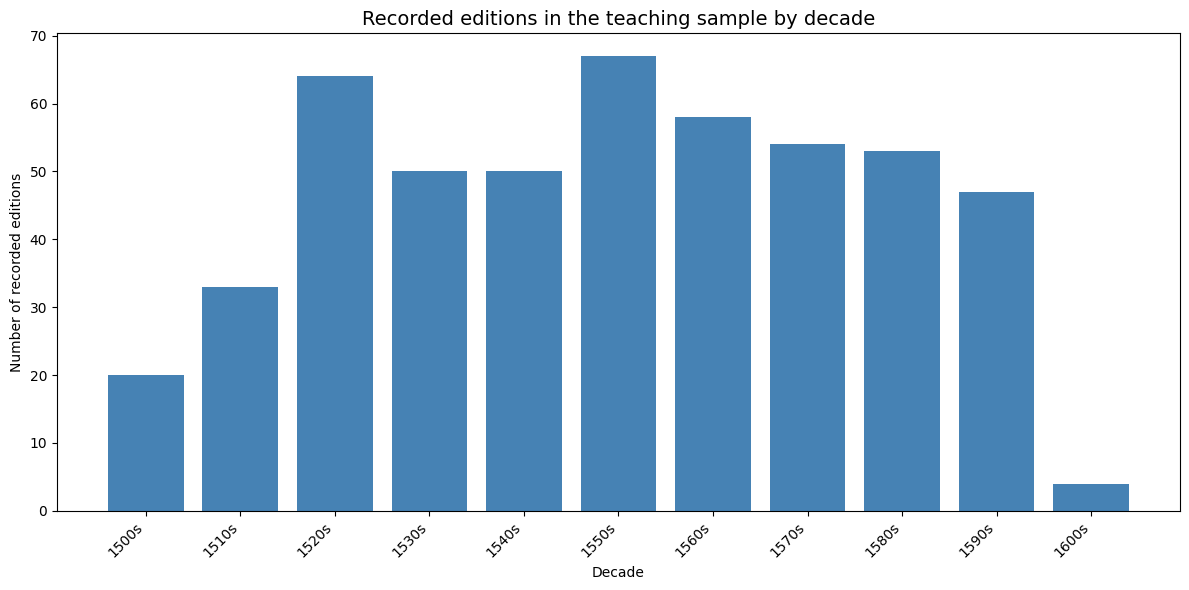


Chart saved as: book-records-by-decade.png


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import re

# --------------------------------------------------
# 1. Load the original CSV file
# --------------------------------------------------

df = pd.read_csv("book-sample.csv")

# Count all original rows
total_records = len(df)

print("Total recorded editions:", total_records)


# --------------------------------------------------
# 2. Count records by decade
# --------------------------------------------------

# Include missing decade values (dropna=False)
decade_counts = (
    df.groupby("decade", dropna=False)
    .size()
    .reset_index(name="record_count")
)

# --------------------------------------------------
# 3. Sort decades chronologically
# --------------------------------------------------

# Extract the starting year from labels like "1530s".
# Missing or unrecognized labels sort to the end.

def decade_sort_key(value):
    if pd.isna(value):
        return float("inf")

    match = re.match(r"^\s*(\d{4})s\s*$", str(value))

    if match:
        return int(match.group(1))

    return float("inf")


decade_counts["sort_key"] = (
    decade_counts["decade"].apply(decade_sort_key)
)

decade_counts = (
    decade_counts
    .sort_values("sort_key", kind="stable")
    .drop(columns="sort_key")
    .reset_index(drop=True)
)

# Make missing decade labels visible
decade_counts["decade"] = (
    decade_counts["decade"]
    .fillna("Missing decade")
    .astype(str)
)


# --------------------------------------------------
# 4. Print and validate the aggregated table
# --------------------------------------------------

print("\n=== RECORDED EDITIONS BY DECADE ===")
print(decade_counts.to_string(index=False))

# Check that no records were lost during aggregation
assert decade_counts["record_count"].sum() == total_records, (
    "Error: Bar counts do not equal the input row count."
)

print("\nValidation passed: all input rows are counted.")


# --------------------------------------------------
# 5. Create the bar chart
# --------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    decade_counts["decade"],
    decade_counts["record_count"],
    color="steelblue"
)

# Use historically accurate wording
plt.title(
    "Recorded editions in the teaching sample by decade",
    fontsize=14
)

plt.xlabel("Decade")
plt.ylabel("Number of recorded editions")

# Start the numerical axis at zero
plt.ylim(bottom=0)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.tight_layout()


# --------------------------------------------------
# 6. Save and display the chart
# --------------------------------------------------

plt.savefig(
    "book-records-by-decade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nChart saved as: book-records-by-decade.png")


Prompt used:
"revise the code to achieve the following: the count of recorded editions for each decade should be dispalyed above the bars in the generated chart."

Total recorded editions: 500

=== RECORDED EDITIONS BY DECADE ===
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4

Validation passed: all input rows are counted.


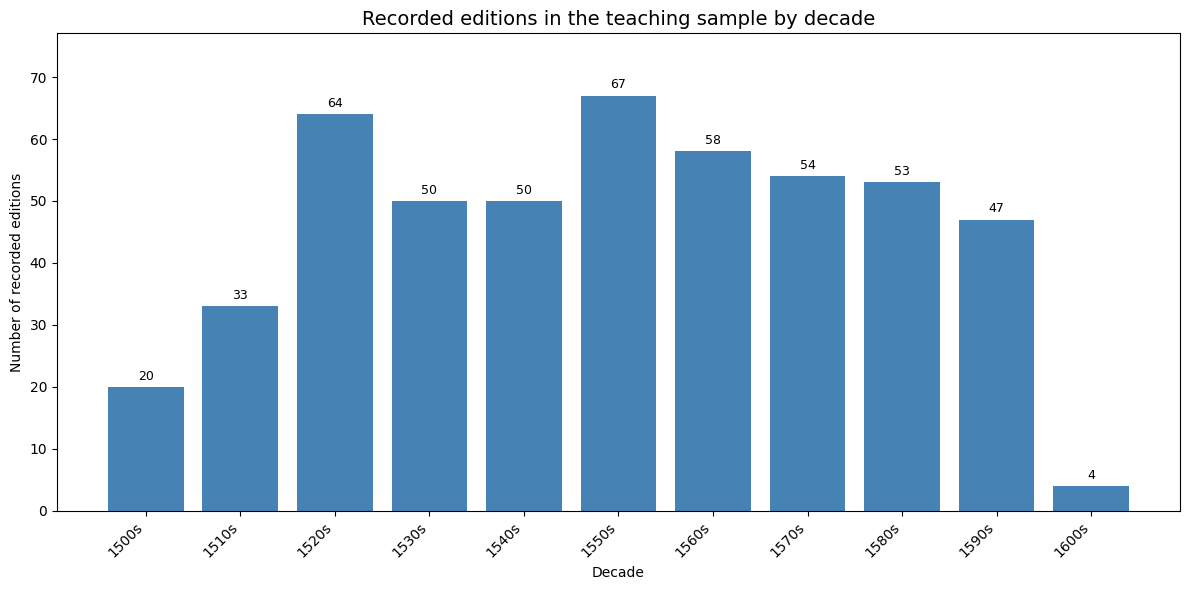


Chart saved as: book-records-by-decade.png


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import re

# --------------------------------------------------
# 1. Load the original CSV file
# --------------------------------------------------

df = pd.read_csv("book-sample.csv")

total_records = len(df)

print("Total recorded editions:", total_records)


# --------------------------------------------------
# 2. Count records by decade
# --------------------------------------------------

decade_counts = (
    df.groupby("decade", dropna=False)
    .size()
    .reset_index(name="record_count")
)


# --------------------------------------------------
# 3. Sort decades chronologically
# --------------------------------------------------

def decade_sort_key(value):
    if pd.isna(value):
        return float("inf")

    match = re.match(r"^\s*(\d{4})s\s*$", str(value))

    if match:
        return int(match.group(1))

    return float("inf")


decade_counts["sort_key"] = (
    decade_counts["decade"].apply(decade_sort_key)
)

decade_counts = (
    decade_counts
    .sort_values("sort_key", kind="stable")
    .drop(columns="sort_key")
    .reset_index(drop=True)
)

decade_counts["decade"] = (
    decade_counts["decade"]
    .fillna("Missing decade")
    .astype(str)
)


# --------------------------------------------------
# 4. Print and validate the aggregated table
# --------------------------------------------------

print("\n=== RECORDED EDITIONS BY DECADE ===")
print(decade_counts.to_string(index=False))

assert decade_counts["record_count"].sum() == total_records, (
    "Error: Bar counts do not equal the input row count."
)

print("\nValidation passed: all input rows are counted.")


# --------------------------------------------------
# 5. Create the bar chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    decade_counts["decade"],
    decade_counts["record_count"],
    color="steelblue"
)

# NEW: Display the count above each bar
ax.bar_label(
    bars,
    labels=decade_counts["record_count"].astype(str),
    padding=3,
    fontsize=9
)

ax.set_title(
    "Recorded editions in the teaching sample by decade",
    fontsize=14
)

ax.set_xlabel("Decade")
ax.set_ylabel("Number of recorded editions")

# Start the numerical axis at zero
ax.set_ylim(bottom=0)

# Leave extra space above the bars for the labels
max_count = decade_counts["record_count"].max()
if max_count > 0:
    ax.set_ylim(top=max_count * 1.15)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.tight_layout()


# --------------------------------------------------
# 6. Save and display the chart
# --------------------------------------------------

plt.savefig(
    "book-records-by-decade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nChart saved as: book-records-by-decade.png")


Prompt used:  
"Create one standalone HTML file for a beginning Digital History student. It should let the user choose a local copy of "book-sample.csv" with an HTML file input, parse it in the browser, count records by the existing decade column, and display an accessible interactive bar chart.\
\
Here is an excerpt of the csv:\


| **edition_id** | **short_title**                                                                                                                                | **author**            | **printer**        | **place**  | **year** | **language** | **format** | **country**         | **year_numeric** | **decade** |
| -------------- | ---------------------------------------------------------------------------------------------------------------------------------------------- | --------------------- | ------------------ | ---------- | -------- | ------------ | ---------- | ------------------- | ---------------- | ---------- |
| 627908         | Das Newe   Testament                                                                                                                           |                       | Kunigunde   Hergot | Nürnberg   | 1535     | German       | 8o         | Holy Roman   Empire | 1535             | 1530s      |
| 698366         | Trewung vom liebebande oder hertztrewen. Item:   hochzeitpredigt von den ursachen warumb einer gerne Freyen solle                              | Streuber, Peter       | Zacharias Bärwald  | Leipzig    | 1590     | German       | 8o         | Holy Roman Empire   | 1590             | 1590s      |
| 691468         | Romischer   Keyserlicher Majestat ordnung und Reformation gueter pollicei im heyligen   Roemischen Reich anno M.D.XXX. zä Augspurg uffgericht. |                       | Johann Schöffer    | Mainz      | 1530     | German       | 2o         | Holy Roman   Empire | 1530             | 1530s      |
| 708446         | Zwo predigten vom gantzen Christlichen wesen und leben                                                                                         | Spangenberg, Cyriacus | Samuel Emmel       | Strasbourg | 1564     | German       | 8o         | Holy Roman Empire   | 1564             | 1560s      |

\
\
Requirements:\
\- Use HTML, CSS, and vanilla JavaScript in one file.\
\- Do not require Python, a web server, npm, or a build step.\
\- Do not upload the CSV anywhere.\
\- Show the aggregated table as well as the chart.\
\- Sort decades chronologically and make the numerical axis begin at zero.\
\- State clearly that the bars count recorded editions in a teaching sample.\
\- Show a useful error for an absent decade column or malformed CSV.\
\- Include comments and then explain how to save and open the file.\
\- If you use an external library, name it, explain that internet access is required, and load it only from its official CDN. Prefer a solution that does not need an external library."

The result can be found within the github-repository!

--

Prompt used:  
"Create one standalone HTML file that lets a user choose a local CSV file and then displays it as a searchable, filterable table. Design it for "historic_photographs_sample_dataset.csv".\
\
Here is an excerpt of the first rows:\


| **Column1** | **Column2**                                        | **Column3**      | **Column4** | **Column5** | **Column6** | **Column7**              | **Column8**            | **Column9**          | **Column10**              | **Column11**            | **Column12**       | **Column13** | **Column14**         | **Column15**          | **Column16**       | **Column17**  |
| ----------- | -------------------------------------------------- | ---------------- | ----------- | ----------- | ----------- | ------------------------ | ---------------------- | -------------------- | ------------------------- | ----------------------- | ------------------ | ------------ | -------------------- | --------------------- | ------------------ | ------------- |
| record_id   | title_raw                                          | creator_raw      | date_raw    | place_raw   | country_raw | subject_raw              | object_type_raw        | caption_language_raw | holding_institution_raw   | rights_raw              | box_folder_raw     | filename_raw | notes_raw            | creator_authority_uri | place_wikidata_qid | lcsh_subjects |
| PHO-001     | Street scene near the Ringstrasse, Vienne          | Abbott, Berenice | 1930-1931   |  Wien       | Austria     | street markets / vendors | albumen print          | English              | City Visual Archive       | Public Domain           | Box 4 / Folder 8   | img_001.jpeg |                      |                       |                    |               |
| PHO-002     |   Workers leaving the Wenceslas Square,   Prague   | dorothea lange   | 1891        | Praha       | Czech Rep.  | ports, ships             | gelatin silver   print | French               | Municipal Photo   Archive | No known   restrictions | Box 6 / Folder   4 | img_002.jpg  | possible   duplicate |                       |                    |               |
| PHO-003     | Rain on the Rossio, Lisboa                         | W. Evans         | 1896?       | lisbon      | Portugal    | factory labor            | gelatin silver print   | n/a                  | Civic Museum Photo Dept.  | No known restrictions   | Box 6 / Folder 19  | img_003.jpg  | cropped print        |                       |                    |               |

\
\
Requirements:\
\- Use HTML, CSS, and vanilla JavaScript in one file.\
\- Do not require Python, a web server, npm, or a build step.\
\- Do not upload the CSV anywhere.\
\- Provide a keyword search across all displayed fields.\
\- Provide dropdown filters for country_raw and object_type_raw.\
\- Display the number of visible records and the total number of records.\
\- Allow sorting by clicking column headers.\
\- Preserve the original cell text; do not normalize values silently.\
\- Treat cell contents as text, not executable HTML, to reduce script-injection risk.\
\- Handle quoted commas and UTF-8 characters correctly.\
\- Show useful messages if the expected columns are absent.\
\- Make the table keyboard-accessible and usable on a narrow screen.\
\- Add comments and explain how to save, open, and test the file."

The result can be found within the github-repository!